In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

In [2]:
main_df = pd.read_excel(r"C:\Users\LoganFrideley\East Texas Salt Water Disposal Company\Operations - Documents\Engineering\Disposal Wells\Workover Analysis\Derived All Data.xlsx")
print(main_df.columns)

Index(['Name', 'Year-Month', 'Hours', 'Water Total', 'PSI', 'Revenue',
       'Metered DM', 'Power Factor', 'Billed DM', 'Billing KWH', 'Fuel Rate',
       'Electrical Bill', 'Workover Info', 'Workover Cost', 'Pump Model',
       'Pump Number', 'Plunger Size', 'Install Date', 'Maintenance Cost',
       'Maintenance Comments', 'KWH per Barrel', 'Cost per KWH',
       'Electrical Cost per Barrel', 'Maintenance Cost per Barrel',
       'Workover Cost per Barrel', 'Revenue per Barrel', 'Income per Barrel',
       'Income', 'Total Cost', '6 Month Avg Water Total', '6 Month Avg KWH',
       '6 Month Avg Revenue', '6 Month Avg Income', '6 Month Avg Total Cost',
       '6 Month Avg KWH per Barrel Weighted', '6 Month Avg Cost per KWH',
       '6 Month Avg Electrical Cost per Barrel',
       '6 Month Avg Maintenance Cost per Barrel',
       '6 Month Avg Workover Cost per Barrel',
       '6 Month Avg Revenue per Barrel', '6 Month Avg Income per Barrel',
       'Cumulative Electrical Cost', 'Cumul

In [4]:
pd.set_option("display.max_rows", None)

#Replacing the Nan pump model values with valid entries
filt_df = main_df[["Name", "Pump Model"]]
na_filt = filt_df["Pump Model"].isna()
wells_and_pumps = filt_df[~na_filt]
wells = main_df["Name"].unique()
print(wells)
pumps = main_df["Pump Model"].unique()
print(pumps)

pump_mapping = (
    wells_and_pumps
    .drop_duplicates(subset=["Name"])
    .set_index("Name")["Pump Model"]
)

print(pump_mapping)
main_df["Pump Model"] = main_df["Pump Model"].fillna(
    main_df["Name"].map(pump_mapping)
)

# which wells in pump_mapping (wells that are mapped to a pump), do not have
# a pump model associated with them?
all_well_set = set(wells)
print(all_well_set)
pump_well_set = set(pump_mapping.index)

missing_pump_set = all_well_set - pump_well_set
print(sorted(list(missing_pump_set)))

print("Missing Pump models remaining:", main_df["Pump Model"].isna().sum())


<StringArray>
[    'ABNEY #2',     'ABNEY #3', 'ALBERTSON #4',      'BASS #4',
      'BASS #5',   'BERWALD #4',   'BERWALD #5',   'BERWALD #6',
 'BLACKWELL #2', 'BLACKWELL #3',      'BLUM #5',      'BLUM #6',
      'BLUM #7',      'BLUM #9',  'BOLDRICK #1',  'BOLDRICK #2',
  'BOLDRICK #3',  'BOLDRICK #4',     'BOLES #1', 'CHRISTIAN #1',
  'COLVILLE #1',  'COLVILLE #3',  'COLVILLE #4',  'COLVILLE #5',
  'COLVILLE #6',    'CUNYUS #1',    'CUNYUS #3',    'CUNYUS #4',
    'CUNYUS #5',    'CUNYUS #6',   'DOWNING #1',   'DOWNING #2',
   'DOWNING #3',   'DOWNING #4',   'DOWNING #5',    'FIELDS #4',
    'FIELDS #6',    'FIELDS #7',     'FRAME #4',     'HAMON #2',
     'HAMON #3',     'HAMON #4',    'HUGHES #3',    'HUGHES #4',
       'KEE #4',       'KEE #5',       'KEE #6',      'LAKE #1',
      'LAKE #2',      'LAKE #3',      'LAKE #4',      'LAKE #5',
      'LAKE #6',   'MERRILL #3',   'MERRILL #4',   'MERRILL #5',
     'MOYAR #2',     'MOYAR #3', 'O'DONNELL #4',     'PAYNE #5',
     'PAYNE

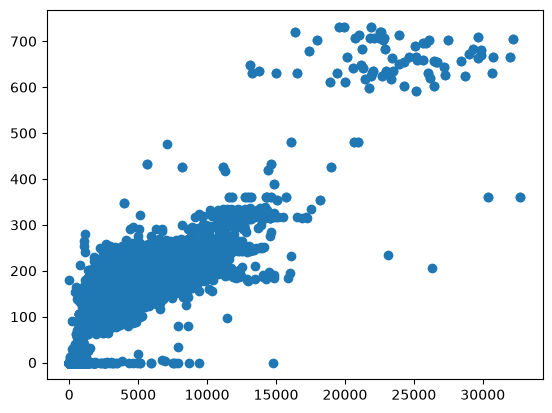

In [34]:
plt.scatter(test_clean["Electrical Bill"], test_clean["Metered DM"])

In [5]:
#scaling the columns of test_clean
scaler = MinMaxScaler()
scaler.fit(test_clean[["Billing KWH"]])
test_clean["Billing KWH"] = scaler.transform(
    test_clean[["Billing KWH"]]
)

scaler.fit(test_clean[["Metered DM"]])
test_clean["Metered DM"] = scaler.transform(
    test_clean[["Metered DM"]]
)

scaler.fit(test_clean[["Electrical Bill"]])
test_clean["Electrical Bill"] = scaler.transform(
    test_clean[["Electrical Bill"]]
)

In [6]:
#establishing the kmeans object as a variable 
#y predicted is an array of the cluster groups
km = KMeans(n_clusters=4)
y_predicted = km.fit_predict(
    test_clean[["Billing KWH", "Metered DM"]]
)


km2 = KMeans(n_clusters=3)
y2_predicted = km2.fit_predict(
    test_clean[["Electrical Bill", "Metered DM"]]
)

In [7]:
#making the y predicted variable, makes an array of the clusters
test_clean["cluster"] = y_predicted
test_clean["cluster2"] = y2_predicted

In [8]:
#attribute that shows the array that displays the coordinates of cluster centers
km.cluster_centers_
km2.cluster_centers_

array([[0.03812694, 0.06711202],
       [0.71655128, 0.87479466],
       [0.19633629, 0.2650756 ]])

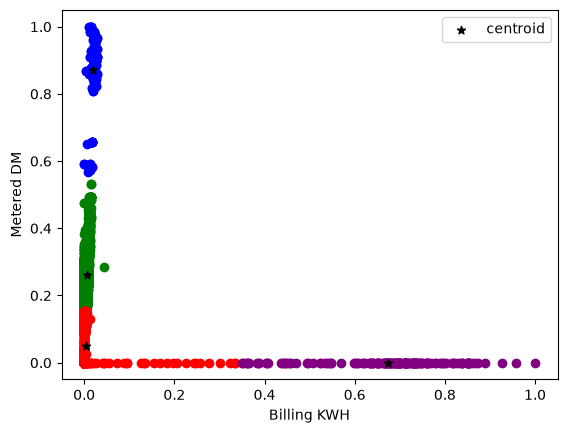

In [9]:
#graph for billing KWH and metered DM  clusteres chart

#making dataframes from cluster values to plot the different clusters in varying colors
df1 = test_clean[test_clean["cluster"] == 0]
df2 = test_clean[test_clean["cluster"] == 1]
df3 = test_clean[test_clean["cluster"] == 2]
df4 = test_clean[test_clean["cluster"] == 3]

plt.scatter(df1["Billing KWH"], df1["Metered DM"], color = "green")
plt.scatter(df2["Billing KWH"], df2["Metered DM"], color = "red")
plt.scatter(df3["Billing KWH"], df3["Metered DM"], color = "purple")
plt.scatter(df4["Billing KWH"], df4["Metered DM"], color = "blue")

#plotting centroid labels
plt.scatter(
    km.cluster_centers_[:,0],
    km.cluster_centers_[:,1],
    color="black",
    marker="*",
    label="centroid"
)

plt.xlabel("Billing KWH")
plt.ylabel("Metered DM")
plt.legend()

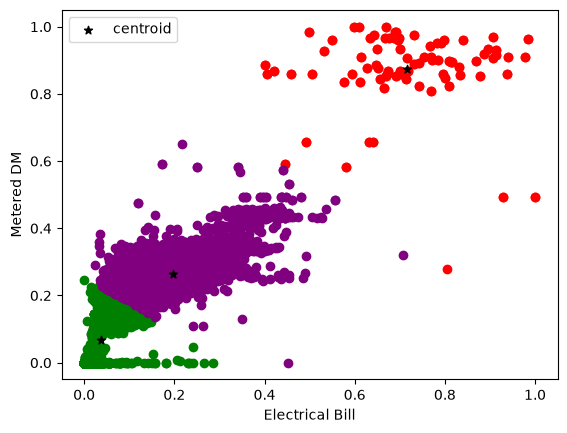

In [10]:
#Graph of electrical bill and metered DM 

#making dataframes from cluster values to plot the different clusters in varying colors
df5 = test_clean[test_clean["cluster2"] == 0]
df6 = test_clean[test_clean["cluster2"] == 1]
df7 = test_clean[test_clean["cluster2"] == 2]

plt.scatter(df5["Electrical Bill"], df5["Metered DM"], color = "green")
plt.scatter(df6["Electrical Bill"], df6["Metered DM"], color = "red")
plt.scatter(df7["Electrical Bill"], df7["Metered DM"], color = "purple")

#plotting centroid labels
plt.scatter(
    km2.cluster_centers_[:,0],
    km2.cluster_centers_[:,1],
    color="black",
    marker="*",
    label="centroid"
)

plt.xlabel("Electrical Bill")
plt.ylabel("Metered DM")
plt.legend()

In [11]:
#making a look for the elbow test
k_rng = range(1,10)
sse = []
for k in k_rng:
    km = KMeans(n_clusters=k)
    km.fit(test_clean[["Electrical Bill", "Metered DM"]])
    sse.append(km.inertia_)

In [12]:
sse

[305.69499798572656,
 176.71096381322877,
 79.41607157396805,
 43.91154882210992,
 30.6752705568567,
 24.635610284325132,
 20.685885648707647,
 18.8037756668455,
 16.641612068615636]

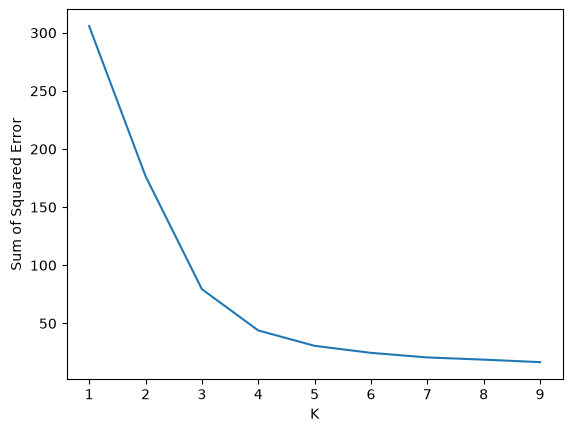

In [13]:
plt.xlabel("K")
plt.ylabel("Sum of Squared Error")
plt.plot(k_rng,sse)

In [14]:
#matching the index of the dataframes to the pump models index
matching_indices = df1.index
print(f"Dataframe index: ",matching_indices)

pump_index = pump.index
print(f"Pump Index: ",pump_index)

mask = matching_indices.isin(pump_index)
print(f"Matching Index: ",matching_indices[mask])

Dataframe index:  Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       8429, 8430, 8432, 8433, 8434, 8435, 8436, 8437, 8438, 8439],
      dtype='int64', length=5904)


NameError: name 'pump' is not defined

In [15]:
pump

NameError: name 'pump' is not defined